# Predictive Customer Churn Classifier

**Dataset:** [IBM Telco Customer Churn](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv)


Train an ensemble machine learning model to predict customer churn using telecom subscription records. Preprocess categorical features using OneHotEncoder, balance class distributions with SMOTE or class weighting, train Logistic Regression, Random Forest and XGBoost classifiers, and evaluate ROC-AUC curve (>80%).

## 1. Setup and reproducibility

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', 30)
print('Environment ready')

Environment ready


## 2. Download the public dataset from Github link

In [4]:
df_raw = pd.read_csv('https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv')
df_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Data-quality audit

In [5]:
audit = pd.DataFrame({
    'dtype': df_raw.dtypes.astype(str),
    'missing_value': df_raw.isna().sum(),
    'unique_value': df_raw.nunique(dropna=False),
    'example': [df_raw[c].iloc[0] if df_raw[c].notna().any() else None for c in df_raw.columns]
    
})
audit

,dtype,missing_value,unique_value,example
customerID,object,0,7043,7590-VHVEG
gender,object,0,2,Female
SeniorCitizen,int64,0,2,0
Partner,object,0,2,Yes
Dependents,object,0,2,No
tenure,int64,0,73,1
PhoneService,object,0,2,No
MultipleLines,object,0,3,No phone service
InternetService,object,0,3,DSL
OnlineSecurity,object,0,3,No


In [6]:
df_raw['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [7]:
df_raw.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
# Inspect text columns for hidden whitespace and inconsistent labels.
text_summary = []
for c in df_raw.select_dtypes(include='object'):
    s = df_raw[c].astype(str)
    text_summary.append({
        'column': c,
        'unique_raw': df_raw[c].nunique(dropna=False),
        'leading_or_trailing_space_rows': int((s != s.str.strip()).sum()),
        'blank_after_strip_rows': int(s.str.strip().eq('').sum())
    })
pd.DataFrame(text_summary).sort_values('blank_after_strip_rows', ascending=False)

,column,unique_raw,leading_or_trailing_space_rows,blank_after_strip_rows
16,TotalCharges,6531,11,11
0,customerID,7043,0,0
1,gender,2,0,0
2,Partner,2,0,0
4,PhoneService,2,0,0
3,Dependents,2,0,0
6,InternetService,3,0,0
7,OnlineSecurity,3,0,0
8,OnlineBackup,3,0,0
5,MultipleLines,3,0,0


### Audit Discussion
- customerID is an identifier, not a feature. Drop it before training
- TotalCharges is not numeric as delivered. Eleven rows have a blank string
- Class imbalance: Churn is the minority class (26%)

In [9]:
df = df_raw.copy()

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip(), errors='coerce')
df['Churn'] = df['Churn'].map({'No': 0,'Yes': 1 })


print('Missing TotalCharges after conversion:', df['TotalCharges'].isna().sum())
print('Target missing:', df['Churn'].isna().sum())
print('Churn rate:', round(df['Churn'].mean(), 3))
df[['tenure','MonthlyCharges','TotalCharges','Churn']].describe().T

Missing TotalCharges after conversion: 11
Target missing: 0
Churn rate: 0.265


,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80
Churn,7043.0,0.265370,0.441561,0.00,0.00,0.000,1.0000,1.00


## 4. Missingness and plausibility

In [10]:
missing = (df.isna().mean().mul(100).round(2).rename('missing_percent')
           .to_frame().query('missing_percent > 0'))
missing

,missing_percent
TotalCharges,0.16


In [35]:
# Investigate the missing values
pd.crosstab(df['TotalCharges'].isna(), df['tenure'], margins=True).iloc[:, :6]

tenure,0,1,2,3,4,5
TotalCharges,,,,,,
False,0,613,238,200,176,133
True,11,0,0,0,0,0
All,11,613,238,200,176,133


## 5. Checking Outlier Values

In [12]:
numeric_for_review = ['tenure','MonthlyCharges','TotalCharges']
outlier_rows=[]
for c in numeric_for_review:
    q1, q3 = df[c].quantile([0.25,0.75])
    iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    outlier_rows.append({'feature':c,'lower_fence':lo,'upper_fence':hi,
                         'flagged_rows':int(((df[c]<lo)|(df[c]>hi)).sum())})
pd.DataFrame(outlier_rows)

,feature,lower_fence,upper_fence,flagged_rows
0,tenure,-60.00000,124.00000,0
1,MonthlyCharges,-46.02500,171.37500,0
2,TotalCharges,-4688.48125,8884.66875,0


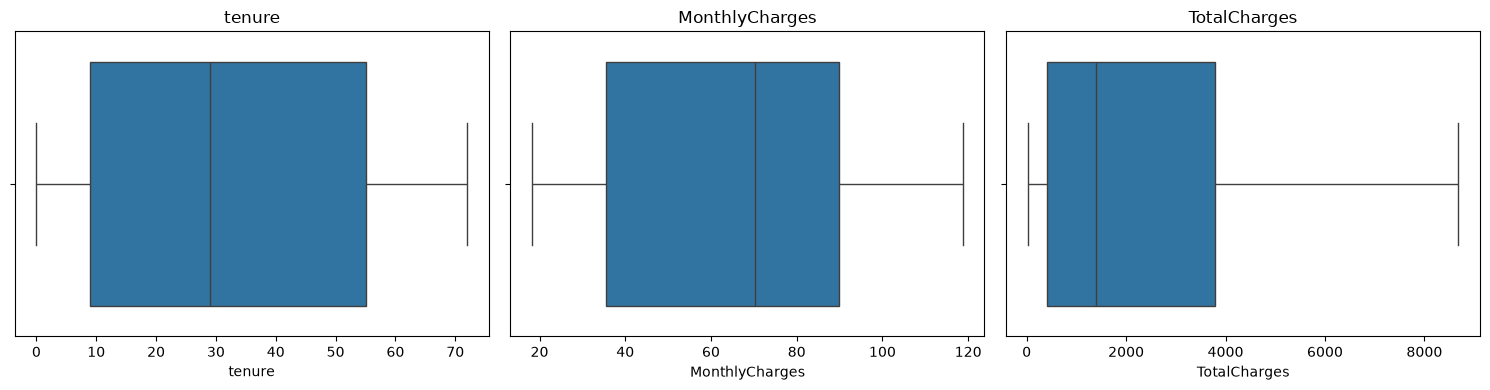

In [37]:
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax,c in zip(axes,numeric_for_review):
    sns.boxplot(x=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

## 6. Train/Test Split & Preprocessing

Exclude `customerID` because it is an identifier. Exclude `Churn` because it is the outcome. All remaining fields require a documented availability check in a real deployment.

In [14]:
target = 'Churn'
identifier = 'customerID'
feature_cols = [c for c in df.columns if c not in [target, identifier]]

X = df[feature_cols]
y = df[target]

train_idx, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_test = X.loc[train_idx], X.loc[test_idx]
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

pd.DataFrame({
    'rows':[len(X_train),len(X_test)],
    'churn_rate':[y_train.mean(),y_test.mean()]
}, index=['train','test'])

,rows,churn_rate
train,5634,0.265353
test,1409,0.265436


In [15]:
df.head(1)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0


In [16]:
numeric_features = ['SeniorCitizen','tenure','MonthlyCharges','TotalCharges']
categorical_features = [c for c in feature_cols if c not in numeric_features]

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='if_binary', handle_unknown='ignore'))
])

preprocess = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])


print('Numeric features:', len(numeric_features))
print('Categorical features:', len(categorical_features))


Numeric features: 4
Categorical features: 15


**Notes:** I use median value for the 11 missing TotalCharges for approximation

In [17]:
# Class-imbalance settings
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()   # ~2.77

models = {
    "LogReg": LogisticRegression(
        max_iter=1000, class_weight='balanced', random_state=SEED
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, class_weight='balanced_subsample',
        random_state=SEED, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        subsample=0.9, colsample_bytree=0.9,
        scale_pos_weight=pos_weight,
        eval_metric='logloss', random_state=SEED, n_jobs=-1
    ),
}
pipelines = {
    name: Pipeline([('preprocess', preprocess), ('model', model)])
    for name, model in models.items()
}

print('Pipelines ready:', list(pipelines.keys()))
print('scale_pos_weight used for XGB:', round(pos_weight, 3))

Pipelines ready: ['LogReg', 'RandomForest', 'XGBoost']
scale_pos_weight used for XGB: 2.769


## 7. Class-imbalance sensitivity: default vs. weighted
Compare each model with and without class weighting under identical stratified CV. 

- Primary metric: ROC-AUC. 

- Secondary: F1, precision, recall. 

Same folds for every run so differences reflect the weighting, not fold variation.

In [47]:
default_models = {
    "LogReg": LogisticRegression(
        random_state=SEED, max_iter=1000
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, random_state=SEED, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
          n_estimators=300, learning_rate=0.05, max_depth=4,
                subsample=0.9, colsample_bytree=0.9,
                eval_metric='logloss', random_state=SEED, n_jobs=-1
    )
}

pipelines_default = {
    name: Pipeline([('preprocess', preprocess), ('model', est)])
    for name, est in default_models.items()
}

# Merge: weighted side from existing `pipelines`, default side from the dict above
pipelines_all = {f"{name} | weighted": pipe for name, pipe in pipelines.items()}
pipelines_all.update(
    {f"{name} | default": pipe for name, pipe in pipelines_default.items()}
)

print(list(pipelines_all.keys()))

['LogReg | weighted', 'RandomForest | weighted', 'XGBoost | weighted', 'LogReg | default', 'RandomForest | default', 'XGBoost | default']


In [48]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ['roc_auc', 'f1', 'precision', 'recall']

results = {}

for name, pipe in pipelines_all.items():
    results[name] = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
    )

print(f"Ran CV for {len(results)} pipelines on {cv.get_n_splits()} folds each.")

Ran CV for 6 pipelines on 5 folds each.


In [49]:
rows = []
for name, res in results.items():
    row = {"model": name}
    for m in scoring:
        row[f"{m}_mean"] = res[f"test_{m}"].mean()
        row[f"{m}_std"]  = res[f"test_{m}"].std()
    rows.append(row)

summary = pd.DataFrame(rows).sort_values("roc_auc_mean", ascending=False)
summary

,model,roc_auc_mean,roc_auc_std,f1_mean,f1_std,precision_mean,precision_std,recall_mean,recall_std
3,LogReg | default,0.846147,0.012558,0.592418,0.029958,0.652083,0.025880,0.543813,0.040885
0,LogReg | weighted,0.845899,0.012424,0.628593,0.023339,0.517389,0.019141,0.801338,0.037933
5,XGBoost | default,0.844524,0.009178,0.579685,0.030207,0.656202,0.035382,0.519732,0.031981
2,XGBoost | weighted,0.844303,0.010148,0.631442,0.012097,0.532078,0.009402,0.776589,0.019547
1,RandomForest | weighted,0.823915,0.012361,0.541679,0.026552,0.634481,0.032502,0.472910,0.026130
4,RandomForest | default,0.823120,0.011922,0.548040,0.021619,0.634279,0.031829,0.482943,0.021004


Did weighting move ROC-AUC? (By how much, for which models?)

Did weighting move recall/precision, and in which direction? (Expect recall ↑, precision ↓.)

Which variant do you carry forward as primary, and why? Tie it to the >0.80 AUC target and to the task's explicit imbalance requirement.